# Permutační důležitost atributů (PFI): co model používá pro predikci zrušení rezervace

**Autor:** Pavlo Romanovyč Prytula

## Zadání

Které atributy jsou nejdůležitější pro predikci zrušení rezervace a jak se jejich význam liší
mezi City Hotelem a Resort Hotelem?

## Metoda

Permutation Feature Importance: hodnoty jednoho atributu v testovacích datech se náhodně zamíchají
(ostatní sloupce i cíl zůstanou, model se nepřetrénovává) a důležitost je pokles ROC-AUC; 20 zamíchání,
mean ± std. ROC-AUC nezávisí na prahu ani na nevyváženosti tříd (37 % zrušení, Appendix E). Míchají se
původní atributy před kódováním. PFI podle hotelu: stejný model, míchá se jen uvnitř hotelu, `hotel`
se vynechává (je tam konstantní).

Model je společný Random Forest z [`../models/rf_model.ipynb`](../models/rf_model.ipynb) (22 atributů
bez data leakage, skupinové rozdělení 80/20; kódování a parametry jsou popsány tam).

## SW

Python 3.12, `pandas`, `numpy`, `matplotlib`, `scikit-learn` (`permutation_importance`), `scipy`
(Cramérovo V, Appendix A); verze v `uv.lock`.

In [1]:
import sys
from itertools import combinations

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from scipy.stats import chi2_contingency
from sklearn.base import clone
from sklearn.inspection import permutation_importance
from sklearn.metrics import get_scorer, roc_auc_score
from sklearn.model_selection import StratifiedGroupKFold, train_test_split
from sklearn.preprocessing import OrdinalEncoder

print("pandas", pd.__version__, "| numpy", np.__version__,
      "| scikit-learn", sklearn.__version__, "| matplotlib", matplotlib.__version__)
%run ../models/rf_model.ipynb

SUBSETS = {"All": X_test["hotel"].notna(),
           "City Hotel": X_test["hotel"] == "City Hotel",
           "Resort Hotel": X_test["hotel"] == "Resort Hotel"}


def auc(X, y, model=pipeline):
    return roc_auc_score(y, model.predict_proba(X)[:, 1])


def perm_drops(X, y, columns, n, rng, base=None):
    # ROC-AUC drops after shuffling `columns` with one shared row permutation, n times
    columns = [columns] if isinstance(columns, str) else columns
    base = auc(X, y) if base is None else base
    drops = []
    for _ in range(n):
        X_perm = X.copy()
        X_perm[columns] = X[columns].iloc[rng.permutation(len(X))].set_index(X.index)
        drops.append(base - auc(X_perm, y))
    return np.array(drops)

pandas 3.1.0 | numpy 2.5.4 | scikit-learn 1.9.1 | matplotlib 3.11.2
Bookings: 118558 | attributes: 22


Train: 94847 | test: 23711 (20.0%)
Feature vectors shared by train and test: 0


,train cancel rate,test cancel rate,test bookings
hotel,,,
City Hotel,0.419,0.419,15778
Resort Hotel,0.280,0.280,7933


ROC-AUC train: 0.956
ROC-AUC test:  0.893
Accuracy test: 0.830
City Hotel: 15778 test bookings, ROC-AUC 0.903
Resort Hotel: 7933 test bookings, ROC-AUC 0.860


## Výsledky

Pokles ROC-AUC po zamíchání atributu na celých testovacích datech a zvlášť v každém hotelu
(vůči výchozímu ROC-AUC daného hotelu); úsečky = std přes 20 zamíchání.

All         City Hotel          \
                                  mean     std       mean     std   
deposit_type                    0.1048  0.0015     0.1284  0.0025   
total_of_special_requests       0.0624  0.0013     0.0728  0.0014   
lead_time                       0.0616  0.0013     0.0449  0.0015   
previous_cancellations          0.0325  0.0006     0.0375  0.0012   
customer_type                   0.0319  0.0016     0.0325  0.0016   
market_segment                  0.0287  0.0010     0.0180  0.0011   
agent                           0.0274  0.0009     0.0303  0.0009   
adr                             0.0111  0.0005     0.0111  0.0006   
hotel                           0.0054  0.0004        NaN     NaN   
arrival_date_month              0.0052  0.0006     0.0066  0.0005   
meal                            0.0034  0.0002     0.0047  0.0004   
adults                          0.0033  0.0002     0.0039  0.0004   
stays_in_week_nights            0.0023  0.0003     0.0015  0.0003   
previous_bookings_not_canceled  0.0021  0.0002     0.0017  0.0001   
distribution_channel            0.0017  0.0002     0.0018  0.0003   
stays_in_weekend_nights         0.0016  0.0003     0.0012  0.0003   
reserved_room_type              0.0014  0.0003     0.0013  0.0002   
company                         0.0007  0.0001     0.0004  0.0001   
children                        0.0006  0.0001     0.0006  0.0001   
is_repeated_guest               0.0005  0.0001     0.0005  0.0001   
days_in_waiting_list            0.0001  0.0001    -0.0001  0.0001   
babies                          0.0000  0.0000    -0.0000  0.0000   

                               Resort Hotel          
                                       mean     std  
deposit_type                         0.0523  0.0016  
total_of_special_requests            0.0464  0.0017  
lead_time                            0.1104  0.0056  
previous_cancellations               0.0222  0.0012  
customer_type                        0.0315  0.0024  
market_segment                       0.0569  0.0027  
agent                                0.0205  0.0015  
adr                                  0.0118  0.0012  
hotel                                   NaN     NaN  
arrival_date_month                   0.0021  0.0006  
meal                                 0.0012  0.0005  
adults                               0.0026  0.0006  
stays_in_week_nights                 0.0040  0.0009  
previous_bookings_not_canceled       0.0042  0.0005  
distribution_channel                 0.0024  0.0008  
stays_in_weekend_nights              0.0026  0.0007  
reserved_room_type                   0.0019  0.0004  
company                              0.0020  0.0003  
children                             0.0006  0.0004  
is_repeated_guest                    0.0007  0.0002  
days_in_waiting_list                 0.0004  0.0001  
babies                               0.0001  0.0000

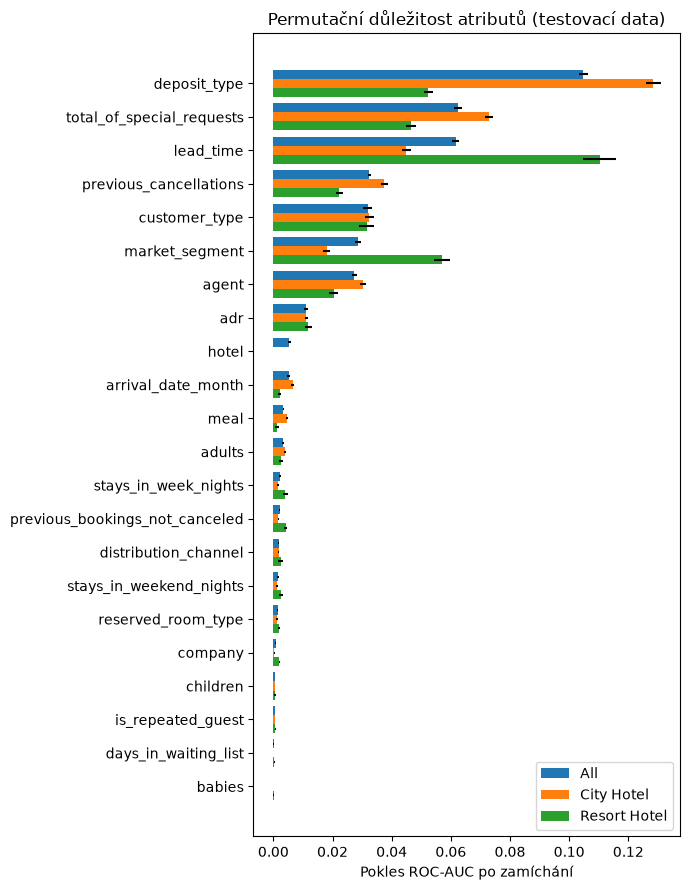

In [2]:
def pfi_table(X, y):
    r = permutation_importance(pipeline, X, y, scoring="roc_auc", n_repeats=20, random_state=SEED)
    return pd.DataFrame({"mean": r.importances_mean, "std": r.importances_std}, index=X.columns)


pfi = {s: pfi_table(X_test[m], y_test[m]) for s, m in SUBSETS.items()}
for h in ["City Hotel", "Resort Hotel"]:
    pfi[h].loc["hotel"] = np.nan
table = pd.concat(pfi, axis=1).sort_values(("All", "mean"), ascending=False)
display(table.round(4))

order, y_pos = table.index[::-1], np.arange(len(table))
fig, ax = plt.subplots(figsize=(7, 9))
for shift, s in [(0.27, "All"), (0, "City Hotel"), (-0.27, "Resort Hotel")]:
    ax.barh(y_pos + shift, table.loc[order, (s, "mean")], xerr=table.loc[order, (s, "std")], height=0.27, label=s)
ax.set_yticks(y_pos, order)
ax.set_xlabel("Pokles ROC-AUC po zamíchání")
ax.set_title("Permutační důležitost atributů (testovací data)")
ax.legend()
plt.tight_layout()
plt.show()

Model nejvíce využívá `deposit_type` (0,105), dále `total_of_special_requests` a `lead_time` (0,062),
pak `previous_cancellations`, `customer_type`, `market_segment` a `agent` (0,027–0,033); `company`,
`children`, `is_repeated_guest`, `days_in_waiting_list` a `babies` téměř vůbec (< 0,001).

Std zachycuje jen náhodu zamíchání, ne nejistotu konečného testovacího vzorku. Podle bootstrapu
(Appendix G) je `deposit_type` první s jistotou (95% interval 0,086–0,115), dvojice
`total_of_special_requests` / `lead_time` a `previous_cancellations` / `customer_type` jsou ale
nerozlišitelné (každý je vyšší zhruba v polovině vzorků), pořadí uvnitř nich proto neinterpretujeme.

## Klíčový detail

**1. Hotely se liší v hlavním signálu.** V City Hotelu je to `deposit_type` (0,128 vs. 0,052 v Resort
Hotelu), v Resort Hotelu `lead_time` (0,110 vs. 0,045) a `market_segment` (0,057 vs. 0,018). 95% bootstrap
intervaly rozdílu City − Resort nulu neobsahují (`deposit_type` 0,045–0,108, `lead_time` −0,080 až
−0,055, `market_segment` −0,048 až −0,034; Appendix G). Odpovídá to datům: nevratné zálohy (`Non Refund`)
jsou zrušené v 99,4 % a tvoří 16,3 % rezervací City Hotelu, ale jen 4,3 % Resort Hotelu (Appendix E).

**Signál typu zálohy je ale nutné brát s rezervou.** `Non Refund` znamená zálohu ve výši celé ceny
pobytu; zrušit ji lze, 99,4 % zrušení je ale neobvyklé. Tyto rezervace tvoří zvláštní shluk (v závorce
ostatní zálohy): 97 % hostů z Portugalska (33 %), 63 % v segmentu `Groups` (10 %), 0,2 % se speciálním
požadavkem (47 %) a 98 % má identickou kopii (31 %; Appendix H). Spíš jde o artefakt záznamu (např.
hromadné skupinové rezervace) než o chování hostů; daty to ověřit nelze. Bez nich (Appendix H) je
v City Hotelu nahoře `total_of_special_requests` (0,098) a `lead_time` (0,076), v Resort Hotelu
`lead_time` (0,130), `market_segment` (0,066) a `total_of_special_requests` (0,052).

**2. Počet speciálních požadavků patří mezi tři nejdůležitější atributy** (0,062, před `market_segment`
i `adr`), víc v City Hotelu (0,073 vs. 0,046; rozdíl 0,017–0,040, Appendix G). Nejde o odraz shluku
`Non Refund`: bez něj je PFI ještě vyšší (0,080). Požadavky lze ale doplnit i po rezervaci: zrušené
rezervace bez zálohy mají požadavek v 16 %, jsou-li zrušené v den vytvoření, v 37–41 %, jsou-li zrušené
později, a nezrušené v 51 % (Appendix J). Část signálu tedy může jen znamenat, že rezervace existovala
aspoň den (nebo chybné rezervace zrušené hned), rozdíl 37–41 % vs. 51 % ale ukazuje, že hlavní signál
zůstává; i vysoké drop-column (0,025, Appendix F) tak částečně odráží informaci známou až po rezervaci.
Popisně jsou rezervace s požadavkem rušeny méně (City Hotel 21,6 % vs. 55,2 %, Resort Hotel 22,2 %
vs. 32,6 %; Appendix E). 4ft úloha z první části našla tento vztah jen v City Hotelu (v Resort Hotelu
nesplnil přísnější práh); model atribut využívá v obou hotelech.

## Omezení interpretace

- **Korelované atributy** si důležitost dělí. Nejsilněji provázaný je prodejní kanál (`agent`,
  `market_segment`, `distribution_channel`, `company`; Cramérovo V až 0,83), `agent` navíc téměř určuje
  hotel (V = 0,88), proto je PFI `hotel` nízká (Appendix A). Společné zamíchání kanálu sníží ROC-AUC
  o 0,080, o 36 % víc než součet individuálních PFI (Appendix D; část mohou tvořit interakce). U historie
  hosta je skupina ≈ součet (poměr 0,96), nízká PFI `is_repeated_guest` tedy nic velkého neskrývá, přestože
  koreluje s `previous_bookings_not_canceled` (Spearman 0,79). `deposit_type` + kanál dají méně než součet
  (0,157 vs. 0,185), ROC-AUC ale není aditivní, takže podhodnocení `deposit_type` to nevylučuje; to
  posuzuje drop-column.
- **Nahraditelnost (drop-column, Appendix F).** Po přetrénování bez `deposit_type` klesne ROC-AUC jen
  o 0,006 (PFI 0,105; v City Hotelu 0,008 vs. 0,128), u `market_segment` o 0,001 (PFI 0,029): informaci
  převezmou jiné atributy. Nejhůř nahraditelné jsou `total_of_special_requests` (0,025), `lead_time`
  (0,016) a `previous_cancellations` (0,014); šum jiného seedu ≤ 0,002. Vysoká PFI tedy neznamená, že
  bez atributu nelze zrušení předpovídat.
- **Anomálie `previous_cancellations`.** Hodnota 1 znamená 94,5 % zrušení, ale 54 % takových rezervací
  je skupinových, 58 % má nevratnou zálohu a jen 11 % je opakovaný host (Appendix E), což odporuje popisu
  atributu (předchozí zrušení téhož zákazníka). PFI není jen odrazem těchto shluků (mimo `Groups` 0,027
  vs. 0,033 celkem, Appendix E; bez `Non Refund` 0,038, Appendix H), jde ale o signál s nejasným obsahem,
  ne o historii hosta. Při časovém rozdělení PFI téměř mizí (Appendix I): na budoucí období se nepřenáší.
- **Umělé případy.** Zamíchání tvoří kombinace, které v datech nejsou (např. City Hotel s pokojem `H`,
  který má jen Resort Hotel). Dolní odhad (Appendix C): u `agent` 47 % a `market_segment` 41 % řádků,
  u `deposit_type` 4 %, u `total_of_special_requests` 3 %, u spojitého `lead_time` neměřitelné. Nevídané
  není nutně nemožné (u `agent` s 334 hodnotami jde hlavně o vzácné kombinace), PFI `agent`
  a `market_segment` je ale spočítaná převážně mimo oblast učení, a tedy méně spolehlivá.
- **Směr a příčinnost.** PFI ukazuje, na co se model spoléhá, ne směr vlivu (zda např. delší `lead_time`
  riziko zvyšuje) ani to, že atribut zrušení způsobuje.
- **Platnost.** Výsledky platí pro tento Random Forest a ROC-AUC. City Hotel má v testu asi dvakrát víc
  rezervací, rozdíly hotelů proto posuzuje bootstrap (Appendix G). Při časovém rozdělení klesne ROC-AUC
  na 0,836, tři hlavní atributy a rozdíl hotelů ale zůstávají (Appendix I).

## Postup při využití AI

- **Návrh a data leakage.** AI (Claude Code) prošlo repozitář a navrhlo plán úlohy. Kandidáty na leakage
  (`required_car_parking_spaces`, `assigned_room_type ≠ reserved_room_type`, `booking_changes`, `country`)
  ověřilo nad daty a navrhlo vyloučit; rozhodnutí o `country` je nejisté.
- **Implementace.** AI napsalo `rf_model.ipynb` a tento notebook, strukturu složek určil autor. Na otázky
  autora doplnilo skupinovou permutaci (Appendix D) a rozšířilo kontroly A a C na všechny dvojice atributů,
  aby každé číslo v textu bylo podložené (Appendix E).
- **Opravené chyby AI.** Původní náhodné rozdělení ignorovalo duplicity: 37 % testovacích rezervací mělo
  kopii v trénovacích datech (ROC-AUC 0,981 vs. 0,831 na ostatních; Appendix E). Po přechodu na skupinové
  rozdělení kleslo ROC-AUC z 0,914 na 0,893, hlavní závěr zůstal. Opraveno i nepodložené tvrzení o korelaci
  počtů nocí, chybný příklad umělého případu a počet Spearmanových dvojic.
- **Nezávislé kontroly (2×).** Dvě další relace AI přepočítaly čísla, model a PFI vlastním skriptem
  (shoda na 3 desetinná místa) a ověřily robustnost (log-loss, jiné seedy, časové rozdělení, hrubší skupiny).
  Našly: špatně přiřazené Cramérovo V 0,88, argument „rozdíl ≫ std“ ignorující nejistotu vzorku, chybějící
  drop-column, nekomentovaný artefakt `Non Refund` (později i příliš silnou formulaci o něm), přehnané
  tvrzení o spolehlivosti `total_of_special_requests`, nepodložený závěr o `deposit_type` ze skupinové
  permutace a nepřesný odkaz na 4ft úlohu → Appendixy F–J.
- **Kontroly správnosti:** Appendix A–J a kontrola v notebooku modelu, že trénovací a testovací data
  nesdílejí žádný vektor atributů.
- **Vlastní práce autora.** Ručně napsané prompty se strukturou řešení a volbou metod; vlastní kontrola
  odpovědí AI a průběžné usměrňování jejího postupu správným směrem.

## Shrnutí

Model předpovídá zrušení dobře na neviděných rezervacích ze stejného období (ROC-AUC ≈ 0,89), na
pozdějším hůř (0,84 při učení na 2015–2016 a testu na 2017). Nejvíce se opírá o typ zálohy, počet
speciálních požadavků a dobu do příjezdu, i při jiném rozdělení dat a jiné metrice. V City Hotelu je
hlavním signálem typ zálohy, v Resort Hotelu doba do příjezdu a segment trhu. Signál zálohy ale pochází
z podezřelého shluku nevratných záloh a model by se bez něj obešel; speciální požadavky lze doplnit
i po rezervaci. Nejsnáze interpretovatelná je proto doba do příjezdu: je známá při rezervaci, ve všech
kontrolách mezi třemi nejdůležitějšími a v resortu hlavní. Pro řízení kapacity: v resortu sledovat dobu
do příjezdu a segment trhu, speciální požadavky spíš jako průběžný signál u existujících rezervací.
Jde o to, na co se model spoléhá, ne o příčiny zrušení ani směr vlivu.

---
# Appendix – kontroly správnosti

## A. Provázané atributy

Všechny dvojice: Spearman (číselné × číselné), Cramérovo V s korekcí zkreslení (diskrétní = kategoriální
a číselné s ≤ 15 hodnotami), korelační poměr η (kategoriální × spojité; u `agent` a `company` s 300+
hodnotami nadsazený). Vypsány dvojice nad 0,3 a dvě ilustrační tabulky.

In [3]:
DISCRETE = CATEGORICAL + [c for c in NUMERIC if df[c].nunique() <= 15]
CONTINUOUS = [c for c in NUMERIC if c not in DISCRETE]
print("Discrete:", DISCRETE, "\nContinuous:", CONTINUOUS)
print("Distinct values of agent / company:", df["agent"].nunique(), "/", df["company"].nunique())


def cramers_v(a, b):
    # bias-corrected Cramer's V (Bergsma 2013)
    t = pd.crosstab(a, b)
    n, (r, k) = t.to_numpy().sum(), t.shape
    phi2 = max(0, chi2_contingency(t, correction=False)[0] / n - (k - 1) * (r - 1) / (n - 1))
    r, k = r - (r - 1) ** 2 / (n - 1), k - (k - 1) ** 2 / (n - 1)
    return np.sqrt(phi2 / min(k - 1, r - 1))


def eta(cat, x):
    # correlation ratio: share of the variance of x explained by cat
    return np.sqrt(((x.groupby(cat).transform("mean") - x.mean()) ** 2).sum() / ((x - x.mean()) ** 2).sum())


corr = df[NUMERIC].corr(method="spearman")
measures = {
    "Spearman |rho|": corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack().dropna(),
    "Cramer's V": pd.Series({(a, b): cramers_v(df[a], df[b]) for a, b in combinations(DISCRETE, 2)}),
    "Correlation ratio": pd.Series({(c, x): eta(df[c], df[x]) for c in CATEGORICAL for x in CONTINUOUS}),
}
for name, m in measures.items():
    print(f"{name} > 0.3 (all {len(m)} pairs):")
    display(m[m.abs() > 0.3].sort_values(key=abs, ascending=False).round(2))

display(pd.crosstab(df["market_segment"], df["distribution_channel"], normalize="index").round(2))
display(pd.crosstab(df["market_segment"], df["agent"] == "none", normalize="index")
        .rename(columns={False: "with agent", True: "no agent"}).round(2))

Discrete: ['hotel', 'meal', 'market_segment', 'distribution_channel', 'reserved_room_type', 'deposit_type', 'customer_type', 'agent', 'company', 'arrival_date_month', 'adults', 'children', 'babies', 'is_repeated_guest', 'previous_cancellations', 'total_of_special_requests'] 
Continuous: ['lead_time', 'stays_in_weekend_nights', 'stays_in_week_nights', 'previous_bookings_not_canceled', 'days_in_waiting_list', 'adr']
Distinct values of agent / company: 334 / 348


Spearman |rho| > 0.3 (all 78 pairs):


is_repeated_guest  previous_bookings_not_canceled    0.79
dtype: float64

Cramer's V > 0.3 (all 120 pairs):


hotel                 agent                     0.88
distribution_channel  agent                     0.83
market_segment        distribution_channel      0.71
                      agent                     0.68
                      company                   0.59
company               is_repeated_guest         0.49
distribution_channel  company                   0.48
deposit_type          agent                     0.47
customer_type         agent                     0.45
meal                  agent                     0.45
market_segment        deposit_type              0.37
reserved_room_type    children                  0.36
market_segment        is_repeated_guest         0.36
agent                 is_repeated_guest         0.33
                      previous_cancellations    0.33
hotel                 reserved_room_type        0.32
distribution_channel  is_repeated_guest         0.31
dtype: float64

Correlation ratio > 0.3 (all 54 pairs):


agent               lead_time                         0.55
company             previous_bookings_not_canceled    0.49
agent               stays_in_week_nights              0.46
reserved_room_type  adr                               0.44
market_segment      lead_time                         0.44
agent               adr                               0.44
market_segment      adr                               0.40
agent               stays_in_weekend_nights           0.40
deposit_type        lead_time                         0.38
agent               days_in_waiting_list              0.36
dtype: float64

distribution_channel,Corporate,Direct,GDS,TA/TO
market_segment,,,,
Aviation,0.96,0.00,0.0,0.04
Complementary,0.11,0.78,0.0,0.11
Corporate,0.90,0.03,0.0,0.06
Direct,0.01,0.97,0.0,0.02
Groups,0.06,0.07,0.0,0.86
Offline TA/TO,0.01,0.00,0.0,0.99
Online TA,0.00,0.00,0.0,0.99


agent,with agent,no agent
market_segment,,
Aviation,0.11,0.89
Complementary,0.14,0.86
Corporate,0.13,0.87
Direct,0.53,0.47
Groups,0.79,0.21
Offline TA/TO,0.98,0.02
Online TA,0.99,0.01


## B. Nezávislá kontrola PFI a výchozího skóre

Ruční výchozí ROC-AUC musí být **přesně** stejné jako skóre `permutation_importance`. Tři atributy se
zamíchají ručně (20×, vlastní generátor); kritérium shody (stanoveno předem): |ruční mean − sklearn mean|
≤ 2 × sklearn std a stejné pořadí.

In [4]:
baseline = auc(X_test, y_test)
print("Manual / sklearn baseline ROC-AUC:", round(baseline, 6), "/",
      round(get_scorer("roc_auc")(pipeline, X_test, y_test), 6))

rng = np.random.default_rng(0)
check = pd.DataFrame({f: perm_drops(X_test, y_test, f, 20, rng).mean() for f in ["deposit_type", "lead_time", "meal"]},
                     index=["manual mean"]).T.join(pfi["All"].add_prefix("sklearn "))
check["match (<= 2 std)"] = (check["manual mean"] - check["sklearn mean"]).abs() <= 2 * check["sklearn std"]
display(check.round(4))
print("Same order:", list(check["manual mean"].sort_values().index) == list(check["sklearn mean"].sort_values().index))

Manual / sklearn baseline ROC-AUC: 0.89279 / 0.89279


,manual mean,sklearn mean,sklearn std,match (<= 2 std)
deposit_type,0.1045,0.1048,0.0015,True
lead_time,0.0610,0.0616,0.0013,True
meal,0.0034,0.0034,0.0002,True


Same order: True


## C. Umělé případy

Dva příklady po jednom zamíchání a systematická kontrola: po zamíchání diskrétního atributu je řádek umělý,
když jeho nová hodnota tvoří s jiným diskrétním atributem dvojici, která se v datech nevyskytuje. Dolní
odhad (jen dvojice, spojité atributy se neměří); nevídané ≠ nutně nemožné.

In [5]:
rng = np.random.default_rng(0)
city, group = X_test["hotel"] == "City Hotel", X_test["customer_type"] == "Group"
room = pd.Series(rng.permutation(X_test["reserved_room_type"].to_numpy()), index=X_test.index)
deposit = pd.Series(rng.permutation(X_test["deposit_type"].to_numpy()), index=X_test.index)
print("City Hotel with room H/L - original:", X_test.loc[city, "reserved_room_type"].isin(["H", "L"]).sum(),
      "| after shuffling:", room[city].isin(["H", "L"]).sum())
print("Group + Non Refund - original:", (X_test.loc[group, "deposit_type"] == "Non Refund").sum(),
      "| after shuffling:", (deposit[group] == "Non Refund").sum())

observed = {(f, g): set(zip(df[f], df[g])) for f in DISCRETE for g in DISCRETE if f != g}
rng = np.random.default_rng(0)
artificial = {}
for f in DISCRETE:
    shuffled = rng.permutation(X_test[f].to_numpy())
    is_art = np.zeros(len(X_test), dtype=bool)
    for g in DISCRETE:
        if g != f:
            is_art |= [p not in observed[(f, g)] for p in zip(shuffled, X_test[g].to_numpy())]
    artificial[f] = is_art.mean()
display(pd.DataFrame({"share of artificial rows": artificial}).join(pfi["All"]["mean"].rename("PFI"))
        .sort_values("share of artificial rows", ascending=False).round(3))

City Hotel with room H/L - original: 0 | after shuffling: 87
Group + Non Refund - original: 0 | after shuffling: 16


,share of artificial rows,PFI
agent,0.468,0.027
market_segment,0.411,0.029
hotel,0.131,0.005
arrival_date_month,0.096,0.005
distribution_channel,0.087,0.002
company,0.051,0.001
reserved_room_type,0.051,0.001
meal,0.050,0.003
deposit_type,0.042,0.105
customer_type,0.028,0.032


## D. Skupinová permutace provázaných atributů

Atributy skupiny se zamíchají jednou společnou permutací řádků (20×), z modelu tak zmizí informace celé
skupiny. Skupina ≈ součet individuálních PFI → informace se nesdílí; skupina > součet → sdílená informace
(nebo interakce), individuální PFI ji podhodnocují; skupina < součet → společná část se počítá vícekrát,
nebo se pokles nasycuje (ROC-AUC není aditivní). Poměr je jen orientační. Skupina `deposit + sales channel`
se porovnává se součtem PFI `deposit_type` a skupiny `sales channel`.

In [6]:
groups = {
    "sales channel": ["market_segment", "distribution_channel", "agent", "company"],
    "guest history": ["is_repeated_guest", "previous_bookings_not_canceled", "previous_cancellations"],
    "length of stay": ["stays_in_weekend_nights", "stays_in_week_nights"],
    "deposit + sales channel": ["deposit_type", "market_segment", "distribution_channel", "agent", "company"],
}
rng = np.random.default_rng(0)
rows = []
for s, m in SUBSETS.items():
    base = auc(X_test[m], y_test[m])
    for g, cols in groups.items():
        d = perm_drops(X_test[m], y_test[m], cols, 20, rng, base)
        rows.append({"subset": s, "group": g, "group mean": d.mean(), "group std": d.std(),
                     "sum of individual": pfi[s].loc[cols, "mean"].sum()})
group_pfi = pd.DataFrame(rows).set_index(["subset", "group"])
group_pfi["group / sum"] = group_pfi["group mean"] / group_pfi["sum of individual"]
display(group_pfi.round(4))

for s in SUBSETS:
    joint = group_pfi.loc[(s, "deposit + sales channel"), "group mean"]
    separate = pfi[s].loc["deposit_type", "mean"] + group_pfi.loc[(s, "sales channel"), "group mean"]
    print(f"{s}: joint {joint:.4f} | deposit_type + sales channel group {separate:.4f} | ratio {joint / separate:.2f}")

group mean  group std  \
subset       group                                            
All          sales channel                0.0798     0.0017   
             guest history                0.0337     0.0008   
             length of stay               0.0051     0.0005   
             deposit + sales channel      0.1571     0.0025   
City Hotel   sales channel                0.0700     0.0021   
             guest history                0.0383     0.0008   
             length of stay               0.0037     0.0005   
             deposit + sales channel      0.1574     0.0033   
Resort Hotel sales channel                0.1120     0.0030   
             guest history                0.0255     0.0020   
             length of stay               0.0069     0.0012   
             deposit + sales channel      0.1499     0.0052   

                                      sum of individual  group / sum  
subset       group                                                    
All          sales channel                       0.0585       1.3632  
             guest history                       0.0352       0.9572  
             length of stay                      0.0039       1.3074  
             deposit + sales channel             0.1633       0.9617  
City Hotel   sales channel                       0.0504       1.3879  
             guest history                       0.0397       0.9641  
             length of stay                      0.0027       1.3577  
             deposit + sales channel             0.1788       0.8802  
Resort Hotel sales channel                       0.0818       1.3687  
             guest history                       0.0271       0.9415  
             length of stay                      0.0066       1.0553  
             deposit + sales channel             0.1342       1.1172

All: joint 0.1571 | deposit_type + sales channel group 0.1846 | ratio 0.85
City Hotel: joint 0.1574 | deposit_type + sales channel group 0.1984 | ratio 0.79
Resort Hotel: joint 0.1499 | deposit_type + sales channel group 0.1643 | ratio 0.91


## E. Popisná čísla citovaná v textu

Z celých dat (118 558 rezervací): podíly zrušení celkem, u `Non Refund` a podle speciálního požadavku,
podíl `Non Refund` v hotelech; profil `previous_cancellations` = 1 a jeho PFI mimo segment `Groups`;
stejný model na náhodném rozdělení 80/20 a podíl testovacích rezervací s kopií v trénovacích datech.

In [7]:
non_refund = df["deposit_type"] == "Non Refund"
print(f"Cancel rate: all {df[TARGET].mean():.1%} | Non Refund {df.loc[non_refund, TARGET].mean():.1%}")
display(non_refund.groupby(df["hotel"]).mean().rename("share of Non Refund bookings").round(3))
has_request = (df["total_of_special_requests"] > 0).map({True: "1+ requests", False: "no request"})
display(pd.crosstab(df["hotel"], has_request, values=df[TARGET], aggfunc="mean").round(3).rename_axis(columns="cancel rate"))

prev = df[df["previous_cancellations"] == 1]
print(f"previous_cancellations = 1: {len(prev)} bookings | cancel rate {prev[TARGET].mean():.1%} | "
      f"Groups {(prev['market_segment'] == 'Groups').mean():.0%} | repeated guest {prev['is_repeated_guest'].mean():.0%} | "
      f"Non Refund {(prev['deposit_type'] == 'Non Refund').mean():.0%}")
ng = X_test["market_segment"] != "Groups"
d = perm_drops(X_test[ng], y_test[ng], "previous_cancellations", 20, np.random.default_rng(0))
print(f"PFI previous_cancellations outside Groups ({ng.sum()} of {len(X_test)} test bookings): "
      f"{d.mean():.4f} ± {d.std():.4f} | all test data: {pfi['All'].loc['previous_cancellations', 'mean']:.4f}")

Cancel rate: all 37.3% | Non Refund 99.4%


hotel
City Hotel      0.163
Resort Hotel    0.043
Name: share of Non Refund bookings, dtype: float64

cancel rate,1+ requests,no request
hotel,,
City Hotel,0.216,0.552
Resort Hotel,0.222,0.326


previous_cancellations = 1: 6044 bookings | cancel rate 94.5% | Groups 54% | repeated guest 11% | Non Refund 58%


PFI previous_cancellations outside Groups (19845 of 23711 test bookings): 0.0273 ± 0.0009 | all test data: 0.0325


In [8]:
# same model on a plain random split; group_ids (identical feature vectors) come from rf_model.ipynb
strata = df["hotel"] + "_" + df[TARGET].astype(str)
idx_train, idx_test = train_test_split(df.index, test_size=0.2, random_state=SEED, stratify=strata)
random_model = clone(pipeline).fit(df.loc[idx_train, FEATURES], df.loc[idx_train, TARGET])
proba = pd.Series(random_model.predict_proba(df.loc[idx_test, FEATURES])[:, 1], index=idx_test)
y_rand = df.loc[idx_test, TARGET]
seen = pd.Series(np.isin(group_ids[idx_test], group_ids[idx_train]), index=idx_test)
print(f"ROC-AUC test (random split): {roc_auc_score(y_rand, proba):.3f} | "
      f"test bookings with an identical copy in train: {seen.mean():.1%}")
display(pd.DataFrame({part: {"bookings": m.sum(), "ROC-AUC": roc_auc_score(y_rand[m], proba[m])}
                      for part, m in [("copy in train", seen), ("no copy in train", ~seen)]})
        .T.astype({"bookings": int}).round(3))

ROC-AUC test (random split): 0.914 | test bookings with an identical copy in train: 37.2%


,bookings,ROC-AUC
copy in train,8823,0.981
no copy in train,14889,0.831


## F. Drop-column: je informace atributu nahraditelná?

Pro atributy s PFI ≥ 0,01 se model přetrénuje bez atributu (stejné parametry i rozdělení) a změří se
pokles ROC-AUC. Šum učení ukazuje rozdíl ROC-AUC modelu přetrénovaného s jiným `random_state`.
Výpočet trvá několik minut.

In [9]:
def subset_auc(model, columns):
    return {s: auc(X_test.loc[m, columns], y_test[m], model) for s, m in SUBSETS.items()}


base_auc = subset_auc(pipeline, FEATURES)
seed_auc = subset_auc(clone(pipeline).set_params(model__random_state=SEED + 1).fit(X_train, y_train), FEATURES)
print("Seed noise |AUC(seed 42) - AUC(seed 43)|:", {s: round(abs(base_auc[s] - seed_auc[s]), 4) for s in base_auc})

rows = {}
for f in pfi["All"].index[pfi["All"]["mean"] >= 0.01]:
    keep = [c for c in FEATURES if c != f]
    encoder = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)
    without = clone(pipeline).set_params(
        preprocess__transformers=[("cat", encoder, [c for c in CATEGORICAL if c != f])]).fit(X_train[keep], y_train)
    auc_without = subset_auc(without, keep)
    rows[f] = {(s, k): v for s in SUBSETS
               for k, v in [("PFI", pfi[s].loc[f, "mean"]), ("drop-column", base_auc[s] - auc_without[s])]}
drop_column = pd.DataFrame(rows).T.sort_values(("All", "PFI"), ascending=False)
display(drop_column.round(4))

Seed noise |AUC(seed 42) - AUC(seed 43)|: {'All': 0.0004, 'City Hotel': 0.0001, 'Resort Hotel': 0.0016}


All             City Hotel              \
                              PFI drop-column        PFI drop-column   
deposit_type               0.1048      0.0062     0.1284      0.0075   
total_of_special_requests  0.0624      0.0249     0.0728      0.0301   
lead_time                  0.0616      0.0163     0.0449      0.0137   
previous_cancellations     0.0325      0.0135     0.0375      0.0148   
customer_type              0.0319      0.0067     0.0325      0.0059   
market_segment             0.0287      0.0011     0.0180      0.0004   
agent                      0.0274      0.0068     0.0303      0.0061   
adr                        0.0111      0.0073     0.0111      0.0078   

                          Resort Hotel              
                                   PFI drop-column  
deposit_type                    0.0523      0.0043  
total_of_special_requests       0.0464      0.0160  
lead_time                       0.1104      0.0248  
previous_cancellations          0.0222      0.0113  
customer_type                   0.0315      0.0095  
market_segment                  0.0569      0.0031  
agent                           0.0205      0.0090  
adr                             0.0118      0.0069

## G. Bootstrap: nejistota PFI z konečného testovacího vzorku

Testovací data se převzorkují 30× (zvlášť v každém hotelu, „All“ = jejich spojení) a PFI se spočítá znovu
(2 zamíchání). Vzorkují se celé skupiny shodných rezervací (`group_ids`), protože kopie nejsou nezávislé.
Výstup: 95% percentilové intervaly PFI, intervaly rozdílu City − Resort a podíl vzorků, v nichž platí
pořadí blízkých dvojic. S 30 vzorky jsou intervaly orientační.

In [10]:
boot_features = ["deposit_type", "total_of_special_requests", "lead_time",
                 "previous_cancellations", "customer_type", "market_segment"]
rng = np.random.default_rng(0)
test_groups = pd.Series(np.arange(len(X_test))).groupby(group_ids[X_test.index]).indices
groups_by_hotel = {h: [g for g, pos in test_groups.items() if X_test["hotel"].iloc[pos[0]] == h]
                   for h in ["City Hotel", "Resort Hotel"]}

rows = []
for b in range(30):
    sample = {h: np.concatenate([test_groups[gs[i]] for i in rng.choice(len(gs), len(gs), replace=True)])
              for h, gs in groups_by_hotel.items()}
    sample["All"] = np.concatenate([sample["City Hotel"], sample["Resort Hotel"]])
    for s, pos in sample.items():
        X, y = X_test.iloc[pos].reset_index(drop=True), y_test.iloc[pos].reset_index(drop=True)
        base = auc(X, y)
        rows.append({"b": b, "subset": s, **{f: perm_drops(X, y, f, 2, rng, base).mean() for f in boot_features}})
boot = pd.DataFrame(rows)


def interval(v):
    return f"[{np.percentile(v, 2.5):.3f}, {np.percentile(v, 97.5):.3f}]"


display(boot.groupby("subset")[boot_features].agg(interval).T)
by = {s: boot[boot["subset"] == s].set_index("b")[boot_features] for s in SUBSETS}
display((by["City Hotel"] - by["Resort Hotel"]).agg(interval).rename("95% interval City - Resort").to_frame())
for a, c in [("total_of_special_requests", "lead_time"), ("previous_cancellations", "customer_type"),
             ("customer_type", "market_segment")]:
    print(f"All: {a} > {c} in {(by['All'][a] > by['All'][c]).mean():.0%} of bootstrap samples")

subset,All,City Hotel,Resort Hotel
deposit_type,"[0.086, 0.115]","[0.102, 0.146]","[0.028, 0.072]"
total_of_special_requests,"[0.057, 0.067]","[0.067, 0.081]","[0.039, 0.053]"
lead_time,"[0.055, 0.069]","[0.040, 0.051]","[0.098, 0.122]"
previous_cancellations,"[0.027, 0.040]","[0.030, 0.044]","[0.015, 0.030]"
customer_type,"[0.027, 0.037]","[0.027, 0.040]","[0.025, 0.038]"
market_segment,"[0.026, 0.033]","[0.014, 0.021]","[0.053, 0.065]"


,95% interval City - Resort
deposit_type,"[0.045, 0.108]"
total_of_special_requests,"[0.017, 0.040]"
lead_time,"[-0.080, -0.055]"
previous_cancellations,"[0.005, 0.023]"
customer_type,"[-0.006, 0.011]"
market_segment,"[-0.048, -0.034]"


All: total_of_special_requests > lead_time in 53% of bootstrap samples
All: previous_cancellations > customer_type in 53% of bootstrap samples
All: customer_type > market_segment in 93% of bootstrap samples


## H. Nevratná záloha (`Non Refund`) a PFI bez ní

Profil rezervací `Non Refund` (země z původního souboru, model `country` nepoužívá) a PFI na testovacích
datech bez nich (5 zamíchání): které atributy model používá mimo tento shluk a zda rozdíl hotelů zůstává.

In [11]:
country = pd.read_csv(DATA_PATH, usecols=["country"])["country"]
group_size = pd.Series(group_ids, index=df.index).map(pd.Series(group_ids).value_counts())
display(pd.DataFrame({part: {
    "bookings": m.sum(),
    "cancel rate": df.loc[m, TARGET].mean(),
    "country PRT": (country[m] == "PRT").mean(),
    "market_segment Groups": (df.loc[m, "market_segment"] == "Groups").mean(),
    "1+ special requests": (df.loc[m, "total_of_special_requests"] > 0).mean(),
    "has an identical copy": (group_size[m] > 1).mean(),
} for part, m in [("Non Refund", non_refund), ("other deposit types", ~non_refund)]}).round(3))

keep = X_test["deposit_type"] != "Non Refund"
print("Test bookings without Non Refund:", keep.sum(), "of", len(X_test))
pfi_no_nr = {}
for s, m in SUBSETS.items():
    m = m & keep
    r = permutation_importance(pipeline, X_test[m], y_test[m], scoring="roc_auc", n_repeats=5, random_state=SEED)
    pfi_no_nr[s] = pd.Series(r.importances_mean, index=X_test.columns)
    print(f"{s}: ROC-AUC without Non Refund {auc(X_test[m], y_test[m]):.3f}")
display(pd.DataFrame(pfi_no_nr).sort_values("All", ascending=False).head(10).round(4))

,Non Refund,other deposit types
bookings,14586.000,103972.000
cancel rate,0.994,0.285
country PRT,0.972,0.325
market_segment Groups,0.629,0.102
1+ special requests,0.002,0.469
has an identical copy,0.983,0.314


Test bookings without Non Refund: 20697 of 23711


All: ROC-AUC without Non Refund 0.838


City Hotel: ROC-AUC without Non Refund 0.838


Resort Hotel: ROC-AUC without Non Refund 0.836


,All,City Hotel,Resort Hotel
lead_time,0.0947,0.0763,0.1304
total_of_special_requests,0.0798,0.0978,0.0521
customer_type,0.0494,0.0580,0.0371
market_segment,0.0425,0.0277,0.0661
agent,0.0404,0.0470,0.0240
previous_cancellations,0.0376,0.0439,0.0248
adr,0.0171,0.0188,0.0132
hotel,0.0085,0.0000,0.0000
arrival_date_month,0.0073,0.0112,0.0025
meal,0.0050,0.0080,0.0015


## I. Jiné rozdělení dat: časové a podle dávek rezervací

Stejné parametry modelu, PFI s 5 zamícháními:

1. **Časové:** učení na příjezdech 2015–2016, test na 2017 (leden–srpen; část poklesu může souviset
   se sezónností).
2. **Podle dávek:** skupinu tvoří rezervace se stejným hotelem, datem příjezdu, `lead_time`, agentem,
   firmou, segmentem, zálohou a typem zákazníka (např. pokoje jedné skupinové objednávky), i když se liší
   cenou, počtem nocí nebo hostů; hlavní rozdělení je nedrží pohromadě.

In [12]:
arrival = pd.read_csv(DATA_PATH, usecols=["arrival_date"], parse_dates=["arrival_date"])["arrival_date"]
batch_cols = ["hotel", "lead_time", "agent", "company", "market_segment", "deposit_type", "customer_type"]
batch_ids = pd.factorize(df[batch_cols].astype(str).agg("|".join, axis=1) + "|" + arrival.astype(str))[0]
print(f"Official split: test bookings whose batch also occurs in train: "
      f"{np.isin(batch_ids[X_test.index], batch_ids[X_train.index]).mean():.1%}")

cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
batch_train, batch_test = next(cv.split(df, strata, batch_ids))
splits = {"temporal (2017)": (df.index[arrival < "2017-01-01"], df.index[arrival >= "2017-01-01"]),
          "batch groups": (df.index[batch_train], df.index[batch_test])}


def pfi_split(train, test):
    model = clone(pipeline).fit(df.loc[train, FEATURES], df.loc[train, TARGET])
    X, y = df.loc[test, FEATURES], df.loc[test, TARGET]
    aucs, pfis = {}, {}
    for s in SUBSETS:
        m = X["hotel"].notna() if s == "All" else X["hotel"] == s
        aucs[s] = auc(X[m], y[m], model)
        r = permutation_importance(model, X[m], y[m], scoring="roc_auc", n_repeats=5, random_state=SEED)
        pfis[s] = pd.Series(r.importances_mean, index=X.columns)
    return len(test), aucs, pfis


results = {"official": (len(X_test), base_auc, {s: pfi[s]["mean"] for s in SUBSETS})}
results |= {name: pfi_split(*split) for name, split in splits.items()}
display(pd.DataFrame({name: {"test bookings": n, **{f"ROC-AUC {s}": round(a, 3) for s, a in aucs.items()}}
                      for name, (n, aucs, _) in results.items()}).T)

pfi_splits = pd.concat({(name, s): p[s] for name, (_, _, p) in results.items() for s in p}, axis=1).reindex(table.index)
pfi_splits.loc["hotel", [c for c in pfi_splits.columns if c[1] != "All"]] = np.nan
display(pfi_splits.round(4))
for c in pfi_splits.columns:
    print(f"{c[0]:>16} | {c[1]:<12} top 3:", list(pfi_splits[c].nlargest(3).index))

Official split: test bookings whose batch also occurs in train: 35.9%


,test bookings,ROC-AUC All,ROC-AUC City Hotel,ROC-AUC Resort Hotel
official,23711.0,0.893,0.903,0.860
temporal (2017),40509.0,0.836,0.841,0.817
batch groups,23712.0,0.886,0.896,0.853


official                          \
                                    All City Hotel Resort Hotel   
deposit_type                     0.1048     0.1284       0.0523   
total_of_special_requests        0.0624     0.0728       0.0464   
lead_time                        0.0616     0.0449       0.1104   
previous_cancellations           0.0325     0.0375       0.0222   
customer_type                    0.0319     0.0325       0.0315   
market_segment                   0.0287     0.0180       0.0569   
agent                            0.0274     0.0303       0.0205   
adr                              0.0111     0.0111       0.0118   
hotel                            0.0054        NaN          NaN   
arrival_date_month               0.0052     0.0066       0.0021   
meal                             0.0034     0.0047       0.0012   
adults                           0.0033     0.0039       0.0026   
stays_in_week_nights             0.0023     0.0015       0.0040   
previous_bookings_not_canceled   0.0021     0.0017       0.0042   
distribution_channel             0.0017     0.0018       0.0024   
stays_in_weekend_nights          0.0016     0.0012       0.0026   
reserved_room_type               0.0014     0.0013       0.0019   
company                          0.0007     0.0004       0.0020   
children                         0.0006     0.0006       0.0006   
is_repeated_guest                0.0005     0.0005       0.0007   
days_in_waiting_list             0.0001    -0.0001       0.0004   
babies                           0.0000    -0.0000       0.0001   

                               temporal (2017)                          \
                                           All City Hotel Resort Hotel   
deposit_type                            0.0971     0.1285       0.0284   
total_of_special_requests               0.0700     0.0866       0.0410   
lead_time                               0.0583     0.0414       0.1144   
previous_cancellations                  0.0029     0.0027       0.0039   
customer_type                           0.0242     0.0221       0.0304   
market_segment                          0.0289     0.0231       0.0487   
agent                                   0.0325     0.0341       0.0311   
adr                                     0.0064     0.0073       0.0056   
hotel                                   0.0069        NaN          NaN   
arrival_date_month                      0.0002     0.0020      -0.0027   
meal                                    0.0020     0.0026       0.0012   
adults                                  0.0046     0.0053       0.0038   
stays_in_week_nights                    0.0031     0.0029       0.0028   
previous_bookings_not_canceled          0.0040     0.0030       0.0074   
distribution_channel                    0.0017     0.0023       0.0010   
stays_in_weekend_nights                 0.0011     0.0012       0.0004   
reserved_room_type                      0.0011     0.0008       0.0006   
company                                 0.0019     0.0016       0.0029   
children                                0.0004     0.0001       0.0005   
is_repeated_guest                       0.0007     0.0006       0.0007   
days_in_waiting_list                    0.0000    -0.0000       0.0000   
babies                                 -0.0001    -0.0000      -0.0002   

                               batch groups                          
                                        All City Hotel Resort Hotel  
deposit_type                         0.0968     0.1188       0.0459  
total_of_special_requests            0.0538     0.0612       0.0409  
lead_time                            0.0610     0.0442       0.1040  
previous_cancellations               0.0332     0.0351       0.0292  
customer_type                        0.0307     0.0305       0.0347  
market_segment                       0.0276     0.0168       0.0527  
agent                                0.0269     0.0291       0.0241  
adr            

        official | All          top 3: ['deposit_type', 'total_of_special_requests', 'lead_time']
        official | City Hotel   top 3: ['deposit_type', 'total_of_special_requests', 'lead_time']
        official | Resort Hotel top 3: ['lead_time', 'market_segment', 'deposit_type']
 temporal (2017) | All          top 3: ['deposit_type', 'total_of_special_requests', 'lead_time']
 temporal (2017) | City Hotel   top 3: ['deposit_type', 'total_of_special_requests', 'lead_time']
 temporal (2017) | Resort Hotel top 3: ['lead_time', 'market_segment', 'total_of_special_requests']
    batch groups | All          top 3: ['deposit_type', 'lead_time', 'total_of_special_requests']
    batch groups | City Hotel   top 3: ['deposit_type', 'total_of_special_requests', 'lead_time']
    batch groups | Resort Hotel top 3: ['lead_time', 'market_segment', 'deposit_type']


- **Časové:** ROC-AUC klesne z 0,893 na 0,836 (City Hotel 0,841, Resort Hotel 0,817). Tři hlavní atributy
  i rozdíl hotelů zůstávají (v Resort Hotelu první `lead_time`, druhý `market_segment`), PFI
  `previous_cancellations` ale klesne z 0,033 na 0,003.
- **Podle dávek:** 35,9 % testovacích rezervací má v hlavním rozdělení „sourozence“ v trénovacích datech.
  ROC-AUC klesne jen mírně (0,886) a pořadí zůstává až na dvojici `total_of_special_requests` /
  `lead_time`, kterou nerozliší ani hlavní výsledky (Appendix G).

## J. Speciální požadavky: doplňují se po rezervaci?

Kdyby požadavky přibývaly s časem, zrušené rezervace by je měly méně jen proto, že existovaly kratší dobu.
Datum zrušení (`reservation_status_date`) je jen v surových datech, ta se načtou stejným čištěním jako
`scripts/prepare_data.py` (řádky odpovídají `df`). Pro zrušené rezervace `No Deposit` (`Non Refund`
požadavky téměř nemá) se podle doby od vytvoření do zrušení počítá podíl s požadavkem, i při `lead_time`
90–240 dní; pro srovnání nezrušené rezervace `No Deposit`.

In [13]:
sys.path.insert(0, "../../../scripts")
import prepare_data

log = []
full = prepare_data.load_raw(prepare_data.RAW_PATH)
full = prepare_data.drop_invalid_rows(prepare_data.add_derived(prepare_data.fix_types(full, log), log), log).reset_index(drop=True)
assert len(full) == len(df) and (full["lead_time"] == df["lead_time"]).all() and (full["hotel"] == df["hotel"]).all()

booked = pd.to_datetime(full["arrival_date"]) - pd.to_timedelta(full["lead_time"], unit="D")
days_alive = (pd.to_datetime(full["reservation_status_date"]) - booked).dt.days
alive_bin = pd.cut(days_alive, [-np.inf, 0, 7, 30, 90, np.inf], labels=["0 (same day)", "1-7", "8-30", "31-90", "91+"])
has_request = df["total_of_special_requests"] > 0
no_deposit, mid_lead = df["deposit_type"] == "No Deposit", df["lead_time"].between(90, 240)
canceled = no_deposit & (df[TARGET] == 1)


def request_share(m):
    return has_request[m].groupby(alive_bin[m], observed=True).agg(["size", "mean"]).set_axis(["bookings", "share with request"], axis=1)


display(pd.concat({"all lead times": request_share(canceled), "lead_time 90-240": request_share(canceled & mid_lead)},
                  axis=1).rename_axis("days from booking to cancellation").round(3))
print(f"Not canceled, No Deposit: share with request {has_request[no_deposit & (df[TARGET] == 0)].mean():.3f} "
      f"(lead_time 90-240: {has_request[no_deposit & mid_lead & (df[TARGET] == 0)].mean():.3f})")
display(has_request[canceled].groupby([df.loc[canceled, "hotel"], alive_bin[canceled]], observed=True).mean().unstack().round(3))

all lead times                     \
                                        bookings share with request   
days from booking to cancellation                                     
0 (same day)                                4119              0.158   
1-7                                         7515              0.389   
8-30                                        6284              0.414   
31-90                                       6019              0.386   
91+                                         5705              0.372   

                                  lead_time 90-240                     
                                          bookings share with request  
days from booking to cancellation                                      
0 (same day)                                   927              0.129  
1-7                                           1945              0.362  
8-30                                          1701              0.417  
31-90                                         2606              0.396  
91+                                           3697              0.401

Not canceled, No Deposit: share with request 0.514 (lead_time 90-240: 0.546)


,0 (same day),1-7,8-30,31-90,91+
hotel,,,,,
City Hotel,0.140,0.370,0.389,0.350,0.350
Resort Hotel,0.201,0.426,0.468,0.467,0.416


- Rezervace zrušené v den vytvoření mají požadavek výrazně méně často (16 %, při `lead_time` 90–240 13 %);
  host ho buď nestihl doplnit, nebo jde o chybné či duplicitní rezervace – data to nerozliší.
- Od prvního dne se podíl téměř nemění (37–41 %) a zůstává pod nezrušenými (51 %, resp. 55 %): požadavky
  s časem soustavně nepřibývají. Atribut je tedy jen částečně informací po rezervaci; v textu je to výhrada,
  ne důvod ho vyloučit.